In [1]:
#Libraries

import yfinance as yf
import pandas as pd
import numpy as np

In [2]:
#Tickers and Data Wrangling
tickers = ["EOAN.DE", "IBE.MC", "TTE.PA", "BP.L", "ENGI.PA", "EQNR.OL"]

data = yf.download(tickers, start="2020-01-01", end="2024-12-31")
prices = data["Close"]
print("First entries for each ticker:")
print(f"{prices.head()}")

#Quick check of NA
print(f"NA Price check per Ticker: {prices.isna().sum()}")

#We carry the last price to avoid NA bc of stock market closure
prices_clean = prices.ffill().dropna()
print(prices_clean.isna().sum())

#Log returns
log_returns = np.log(prices_clean / prices_clean.shift(1)).dropna()
print(log_returns.head())

#Risk profile
print(log_returns.describe())

#Annual data
annual_return = log_returns.mean() * 252
annual_volatility = log_returns.std() * np.sqrt(252)

print("Annual Return:")
print(annual_return)
print("\nAnnual volatility:")
print(annual_volatility)

[*********************100%***********************]  6 of 6 completed

First entries for each ticker:
Ticker            BP.L   ENGI.PA   EOAN.DE     EQNR.OL    IBE.MC     TTE.PA
Date                                                                       
2020-01-02  479.049164  9.530098  7.154590  122.514206  6.905402  32.395969
2020-01-03  492.199707  9.526855  7.088218  124.579636  6.873945  32.763405
2020-01-06  502.212158  9.536584  7.060627  127.367996  6.839493  33.237865
2020-01-07  496.931946  9.656562  7.009917  125.991028  6.706178  33.020401
2020-01-08  492.448792  9.643590  7.033034  126.404099  6.728647  33.106064
NA Price check per Ticker: Ticker
BP.L       23
ENGI.PA     2
EOAN.DE     9
EQNR.OL    26
IBE.MC      4
TTE.PA      2
dtype: int64
Ticker
BP.L       0
ENGI.PA    0
EOAN.DE    0
EQNR.OL    0
IBE.MC     0
TTE.PA     0
dtype: int64
Ticker          BP.L   ENGI.PA   EOAN.DE   EQNR.OL    IBE.MC    TTE.PA
Date                                                                  
2020-01-03  0.027081 -0.000340 -0.009320  0.016718 -0.004566  0.01

In [3]:
#VaR 
#(what's the worst I can lose in a bad day?) If 95%, 95% of days wont surpass this threshold, but 5% will
VaR_95 = log_returns.quantile(0.05)
print(VaR_95)

#Sharpe ratio (Sharpe = Return / volatility)
#To management a portfolio, we have to see how much return do we get per unit of risk. Higher = better
sharpe = annual_return / annual_volatility
print(sharpe)

log_returns.to_csv("log_returns.csv")

#Correlation
correlation = log_returns.corr()
cov_matrix = log_returns.cov() * 252
print(cov_matrix)


Ticker
BP.L      -0.032851
ENGI.PA   -0.021880
EOAN.DE   -0.023139
EQNR.OL   -0.032755
IBE.MC    -0.020455
TTE.PA    -0.029210
Name: 0.05, dtype: float64
Ticker
BP.L      -0.116179
ENGI.PA    0.249287
EOAN.DE    0.330558
EQNR.OL    0.385193
IBE.MC     0.498785
TTE.PA     0.228522
dtype: float64
Ticker       BP.L   ENGI.PA   EOAN.DE   EQNR.OL    IBE.MC    TTE.PA
Ticker                                                             
BP.L     0.132260  0.038910  0.019028  0.079416  0.022091  0.099243
ENGI.PA  0.038910  0.070703  0.034953  0.021627  0.034117  0.037898
EOAN.DE  0.019028  0.034953  0.052479  0.012070  0.028907  0.021509
EQNR.OL  0.079416  0.021627  0.012070  0.114279  0.014120  0.069250
IBE.MC   0.022091  0.034117  0.028907  0.014120  0.050893  0.022885
TTE.PA   0.099243  0.037898  0.021509  0.069250  0.022885  0.103547


In [ ]:
#MONTE-CARLO PORTFOLIO SIMULATION 1 - Data
#Number of random portfolios + weights
n_portfolios = 5000
n_assets = len(tickers)
np.random.seed(42) #Makes the random portfolio reproducible

#Generate random weights that sum  to 1
weights = np.random.random((n_portfolios, n_assets))
weights = weights / weights.sum(axis=1)[:, None]

weights = np.clip(weights, 0.05, 0.40)
weights = weights / weights.sum(axis=1)[:, None]    # Clip weights to stay between 5% and 40% to make realistic portfolios

#Expected annual return + covariance
mu = annual_return.values
cov = cov_matrix.values

#Portfolio returns + volatility
#Portfolio return = weighted average of individual returns
#Portfolio volatility = sqrt(w^T * Cov * w)
#einsum is a fast way to compute this for all 5'000 portfolios at once
port_return = weights.dot(mu)
port_vol = np.sqrt(np.einsum('ij,jk,ik->i', weights, cov, weights))
 

#Sharpe ratio (risk-free=0)
port_sharpe = port_return / port_vol

#Results
results = pd.DataFrame({
    "Return": port_return,
    "Volatility": port_vol,
    "Sharpe": port_sharpe
        })

#Add weights to the Data Frame
weights_df = pd.DataFrame(weights, columns=annual_return.index)
full_results = pd.concat([results, weights_df], axis=1)

full_results.head()

,Return,Volatility,Sharpe,BP.L,ENGI.PA,EOAN.DE,EQNR.OL,IBE.MC,TTE.PA
0,0.070623,0.206780,0.341538,0.126196,0.320330,0.246635,0.201710,0.052568,0.052560
1,0.080108,0.219418,0.365091,0.046486,0.249786,0.173349,0.204193,0.046486,0.279701
2,0.039918,0.253776,0.157295,0.371791,0.094836,0.081208,0.081913,0.135882,0.234370
3,0.058773,0.209902,0.280002,0.202503,0.136533,0.286847,0.065397,0.136962,0.171757
4,0.071362,0.209617,0.340440,0.170349,0.293275,0.074581,0.192074,0.221276,0.048445


Max Sharpe Portfolio:
Return        0.100707
Volatility    0.197782
Sharpe        0.509182
BP.L          0.045959
ENGI.PA       0.045959
EOAN.DE       0.178960
EQNR.OL       0.327816
IBE.MC        0.355346
TTE.PA        0.045959
Name: 862, dtype: float64


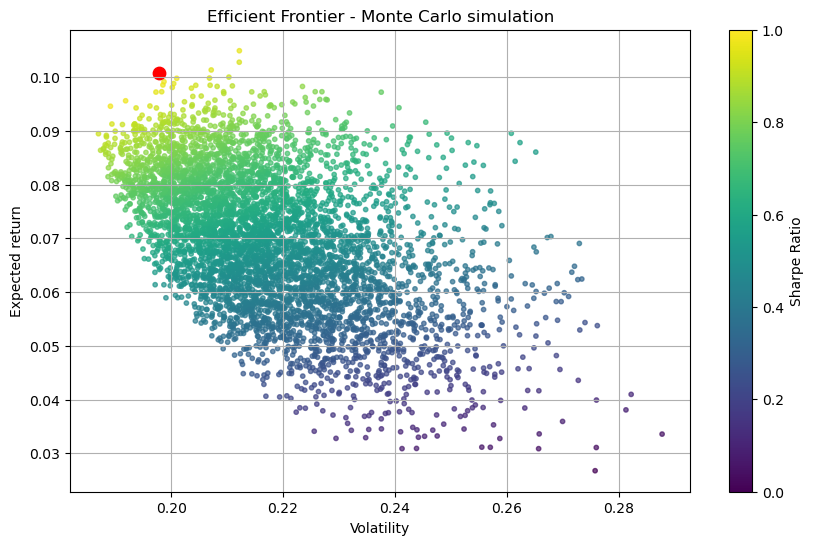

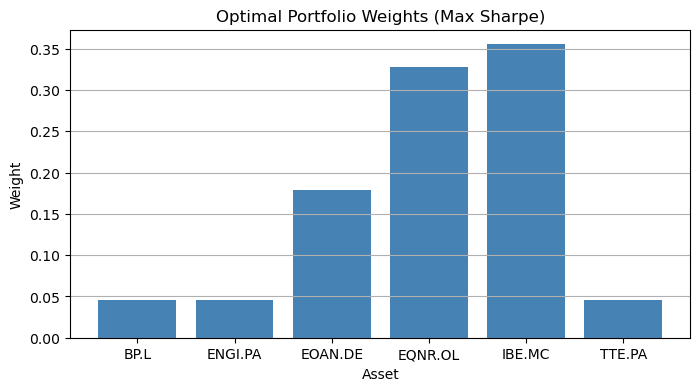

In [ ]:
#MONTE-CARLO PORTFOLIO SIMULATION 2 - Efficient frontier

#Find the portfolio composition with the highest Sharpe ratio
max_sharpe_idx = full_results["Sharpe"].idxmax()

#Extract the full row (return, vol, sharpe, weights)
max_sharpe_port = full_results.loc[max_sharpe_idx]

print("Max Sharpe Portfolio:")
print(max_sharpe_port)

import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))

#Scatter plot of all random portfolios
plt.scatter(
    full_results["Volatility"],
    full_results["Return"],
    c=full_results["Sharpe"],
    cmap="viridis",
    s=10,
    alpha=0.7
)

plt.scatter(
    max_sharpe_port["Volatility"],
    max_sharpe_port["Return"],
    color="red",
    s=80,
    label="Max Sharpe")
        
plt.colorbar(label="Sharpe Ratio")
plt.xlabel("Volatility")
plt.ylabel("Expected return")
plt.title("Efficient Frontier - Monte Carlo simulation")
plt.grid(True)
plt.savefig("efficient_frontier.png", dpi=300, bbox_inches="tight")
plt.show()

#The upper left grid is the efficient frontier, where the risk is lowest and reward is highest

# Optimal portfolio weights as a table
weights_only = max_sharpe_port[annual_return.index]

plt.figure(figsize=(8, 4))
plt.bar(weights_only.index, weights_only.values, color="steelblue")
plt.title("Optimal Portfolio Weights (Max Sharpe)")
plt.ylabel("Weight")
plt.xlabel("Asset")
plt.grid(axis="y")
plt.savefig("optimal_weights.png", dpi=300, bbox_inches="tight")
plt.show()

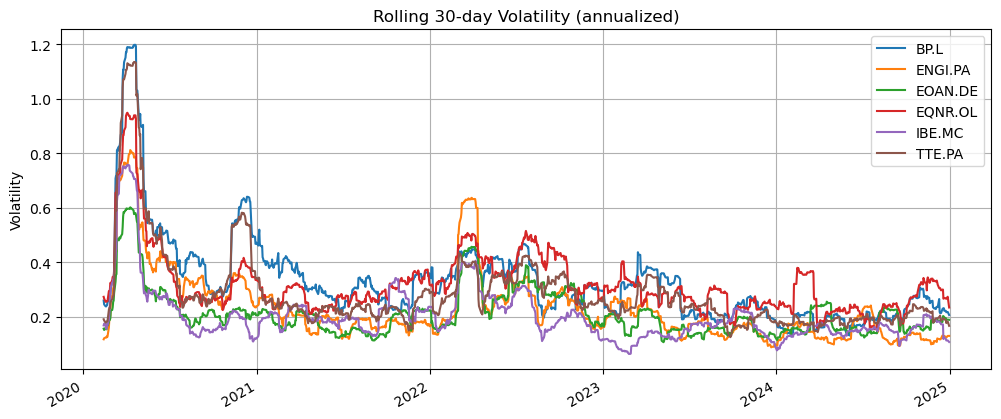

In [6]:
#ROLLING VOLATILITY (30-day window)
rolling_vol = log_returns.rolling(window=30).std() * np.sqrt(252)

rolling_vol.plot(figsize=(12, 5), title = "Rolling 30-day Volatility (annualized)")
plt.xlabel("")
plt.ylabel("Volatility")
plt.legend(loc="upper right")
plt.grid(True)
plt.savefig("rolling_volatility.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
print(rolling_vol.max().round(3))      # peak volatility per stock
print(rolling_vol.idxmax())            # date of each peak

Ticker
BP.L       1.198
ENGI.PA    0.812
EOAN.DE    0.602
EQNR.OL    0.949
IBE.MC     0.758
TTE.PA     1.136
dtype: float64
Ticker
BP.L      2020-04-20
ENGI.PA   2020-04-09
EOAN.DE   2020-04-09
EQNR.OL   2020-04-03
IBE.MC    2020-04-03
TTE.PA    2020-04-17
dtype: datetime64[ns]
